# Hydraulic subdomains: split a rain-on-grid parent at normal-depth locations

This notebook splits the FEMA eBFE **Salt Draw** model (HUC-8 13070004, one 2D
rain-on-grid area of about 794,000 cells) into hydraulic subdomains. It then
builds and runs one headwater subdomain as an independent breakout model and
compares it with the parent.

**The method.** Putting a model boundary where normal depth can be assumed is
standard practice. What this workflow adds is a numerical way to find those
places, from the parent model itself:

1. **Channels and contributing areas** come from the terrain: TauDEM D8 stream
   links and their catchments (`RasTauDem`).
2. **Candidate boundaries** are lines across the valley at pour points (link
   outlets) and in short steps upstream. Each follows the parent's own largest
   downstream face volumes out to the wet edge.
3. **Each candidate is judged as a normal-depth boundary** against the parent's
   native `Face Flow` and cell stage. The comparison runs through the
   conveyance of the parent's own face property tables, at the best single
   friction slope (`RasSubdomain.find_split_lines`).
4. **Subdomain extents** are traced from the parent's cell-to-cell drainage and
   nested into tiers, upstream first (`RasSubdomain.build_subdomains`).
5. **Breakout models** keep the parent's exact cells (cookie cut). Each gets a
   Normal Depth outlet at the fitted slope, Normal Depth along the parent
   perimeter, and an inflow hydrograph from each subdomain upstream
   (`plan_breakouts`, `apply_breakouts`, `validate_breakouts`).

A subdomain with simple normal-depth boundaries is a faithful breakout only
where normal depth holds. Flat, backwater-controlled reaches yield few
accepted lines, and the search reports that rather than forcing a split.

**Scope.** This is a proof of concept. It solves **one headwater subdomain**
and compares it with the parent. The full-HUC tiered run and the parity proof
come later. The fim-commander research behind this port ran the whole HUC as
six children plus the main channel. The main channel reproduced the parent's
1% AEP maximum WSE within 0.008 ft (p95 over 466,000 cells), and the outlet
peak within 0.2%.

**Caching.** Every stage writes to `WORK_ROOT` and is skipped when its output
already exists. Download, organization and the parent run therefore happen once
per machine, and later runs of the notebook start from copies.

In [1]:
import json
import os
import shutil
import sys
import time
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display


def find_repo_root(start: Path) -> Path:
    for candidate in [start, *start.parents]:
        if (candidate / "ras_commander").is_dir() and (candidate / "setup.py").exists():
            return candidate
    return start


REPO_ROOT = find_repo_root(Path.cwd())
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from ras_commander import RasCmdr, RasPlan, RasPrj, init_ras_project
from ras_commander.geom import GeomMesh
from ras_commander.hdf import HdfMesh
from ras_commander.sources.federal.ebfe_models import RasEbfeModels
from ras_commander.subdomain import RasSubdomain, SplitLineCriteria
from ras_commander.subdomain._parent import read_geometry, same_geometry
from ras_commander.terrain import RasTauDem

# Where every stage writes; reruns reuse what is already there.
WORK_ROOT = Path(os.environ.get("RAS_SUBDOMAIN_WORK", Path.home() / "ras-commander-work" / "237_salt_draw"))
# Optional: a local 13070004_Models.zip, a folder holding it, or the extracted delivery.
# Without it the organizer downloads the 67 GB FEMA archive into WORK_ROOT/download.
EBFE_SOURCE = os.environ.get("SALT_DRAW_EBFE_SOURCE")
# Optional: an existing HEC-RAS 6.6 run of the prepared parent with native Face Flow.
# Without it the notebook runs the parent once (about 12.5 h on a fleet node).
PARENT_FACEFLOW_HDF = os.environ.get("SALT_DRAW_PARENT_FACEFLOW_HDF")
# Optional: the folder holding the prepared 6.6 parent geometry (SLDR_004.g02 and .g02.hdf)
# that produced PARENT_FACEFLOW_HDF. Without it the notebook repairs the delivered mesh.
PARENT_GEOMETRY = os.environ.get("SALT_DRAW_PARENT_GEOMETRY")
HECRAS_VERSION = "6.6"
NUM_CORES = int(os.environ.get("RAS_SUBDOMAIN_CORES", "4"))

ORGANIZED = Path(os.environ.get("SALT_DRAW_ORGANIZED", WORK_ROOT / "01_organized"))
PARENT_ROOT = WORK_ROOT / "02_parent"
TAUDEM_DIR = WORK_ROOT / "03_taudem"
BREAKOUT_DIR = WORK_ROOT / "05_breakout"
FIG_DIR = REPO_ROOT / "examples" / "assets" / "237_hydraulic_subdomain_breakout"
for folder in (WORK_ROOT, FIG_DIR):
    folder.mkdir(parents=True, exist_ok=True)
print("work root:", WORK_ROOT)
print("TauDEM:", RasTauDem.get_taudem_info()["executables"]["StreamNet"])

work root: C:\Users\bill\AppData\Local\clb-gen3\scratch-subdomains\nb-work
TauDEM: C:\Program Files\TauDEM\TauDEM5Exe\StreamNet.exe


## 1. Organize the eBFE delivery

`RasEbfeModels.organize_salt_draw` checks the archive identity and extracts the
RAS submittal. Only the 1% AEP result HDF (`p01`, 9 GB) is extracted; the other
six events are left in the archive.

In [2]:
project_dir = ORGANIZED / "RAS Model" / "RAS_Submittal"
if not (project_dir / "Input" / "SLDR_004.prj").is_file():
    t0 = time.time()
    RasEbfeModels.organize_salt_draw(
        downloaded_folder=EBFE_SOURCE or WORK_ROOT / "download",
        output_folder=ORGANIZED,
        output_plans=["p01"],
        include_hms=False,
    )
    print(f"organized in {(time.time() - t0) / 60:.1f} min")
delivered = RasPrj()
init_ras_project(project_dir / "Input", HECRAS_VERSION, ras_object=delivered, load_results_summary=False)
display(delivered.plan_df[["plan_number", "Plan Title", "geometry_number", "unsteady_number"]])

2026-10-24 11:37:41 - ras_commander.RasPrj - INFO - ras-commander v0.96.2 | An open-source project of CLB Engineering Corporation (https://clbengineering.com/) | Docs: https://rascommander.info | GitHub: https://github.com/gpt-cmdr/ras-commander


2026-10-24 11:37:41 - ras_commander.RasPrj - INFO - Project initialized: SLDR_004


2026-10-24 11:37:41 - ras_commander.RasPrj - INFO - Using HEC-RAS version 6.6


2026-10-24 11:37:41 - ras_commander.RasPrj - INFO - 
═══════════════════════════════════════════════════════════════════════
ras-commander | HEC-RAS Automation Library
Docs: https://rascommander.info/ras/
Repo: https://github.com/gpt-cmdr/ras-commander
LLM agents: https://rascommander.info/ras/llms.txt
═══════════════════════════════════════════════════════════════════════

SUPPORT OPEN-SOURCE DEVELOPMENT:
  Using RAS Commander? Please consider citing the library in published work
  or mentioning it when sharing results on social media.
  Agents are encouraged to suggest a RAS Commander v0.96.2 software
  citation when helping prepare reports, publications, and other shared work.
  Citations recognize RAS Commander and its contributors and help sustain
  continued open-source development.
  Citation and sharing guidance: https://rascommander.info/ras/cite/

PROJECT DATAFRAMES (single source of truth — use these, not file globbing):
  ras_object.plan_df        Plans, HDF paths, geometry

,plan_number,Plan Title,geometry_number,unsteady_number
0,01,SLDR_004_1pct,02,01
1,02,SLDR_004_0_2pct,02,02
2,03,SLDR_004_10pct,02,03
3,04,SLDR_004_4pct,02,04
4,05,SLDR_004_2pct,02,05
5,06,SLDR_004_1plu,02,06
6,07,SLDR_004_1min,02,07


## 2. Prepare the parent once

The delivered model was built in HEC-RAS 6.4.1, and its results have no native
`Face Flow`. Two changes make it the parent of this workflow:

- **Mesh repair.** HEC-RAS 6.6 refuses 48 cells of the delivered mesh that have
  more than eight sides. `GeomMesh.plan_computation_point_repair` applies the
  recorded Salt Draw recipe to the delivered computation points. Up to seven
  MaxFaces repairs add longest-face midpoint seeds. Every addition is recorded.
- **Native Face Flow.** `RasPlan.add_hdf_output_variable` adds `Face Flow` to
  plan `01` (1% AEP), and the plan is run once in 6.6. Geometry, forcing, losses
  and solver settings stay as delivered.

The parent working copy leaves out the delivered result HDFs. If
`SALT_DRAW_PARENT_FACEFLOW_HDF` names an existing 6.6 Face Flow run, the
notebook uses it instead of running the parent, together with the prepared
geometry that run used (`SALT_DRAW_PARENT_GEOMETRY`). It first proves the run
and the geometry share an identical mesh.

This executed copy uses the 6.6 parent prepared for the fim-commander Salt Draw
research: the delivered mesh plus 98 longest-face midpoint seeds, checked at the
model's face-length ratio of 0.05. ras-commander's
`plan_computation_point_repair` also requires a complete mesh at ratios 0.0025
and 0.1. On Salt Draw it removes every cell over eight sides, but HEC-RAS still
reports `CellAreaTotalError` at ratio 0.1, so this notebook does not use it yet.

In [3]:
parent_dir = PARENT_ROOT / "RAS_Submittal"
if not (parent_dir / "Input" / "SLDR_004.prj").is_file():
    shutil.copytree(project_dir, parent_dir,
                    ignore=lambda folder, names: [n for n in names if n.lower().endswith(".p01.hdf")])
parent = RasPrj()
init_ras_project(parent_dir / "Input", HECRAS_VERSION, ras_object=parent, load_results_summary=False)
geometry_hdf = parent_dir / "Input" / "SLDR_004.g02.hdf"
repair_marker = PARENT_ROOT / "mesh_repair.json"
if PARENT_GEOMETRY and not repair_marker.is_file():
    for name in ("SLDR_004.g02", "SLDR_004.g02.hdf"):
        shutil.copy2(Path(PARENT_GEOMETRY) / name, parent_dir / "Input" / name)
    repair_marker.write_text(json.dumps({"source": "prepared parent geometry", "folder": str(PARENT_GEOMETRY)}))
if not repair_marker.is_file():
    seeds = HdfMesh.get_mesh_cell_points(project_dir / "Input" / "SLDR_004.g02.hdf", include_ghost_cells=False)
    seeds = np.c_[seeds.geometry.x, seeds.geometry.y]
    t0 = time.time()
    repair = GeomMesh.plan_computation_point_repair("02", seeds, mesh_name="SLDR_004", ras_object=parent)
    GeomMesh.apply_computation_point_repair(repair)
    repair_marker.write_text(json.dumps(repair.to_dict(), default=str, indent=1))
    print(f"mesh repair planned and applied in {(time.time() - t0) / 60:.1f} min")
repair_record = json.loads(repair_marker.read_text())
print({k: v for k, v in repair_record.items() if not isinstance(v, (list, dict))})

2026-10-24 11:37:41 - ras_commander.RasPrj - INFO - ras-commander v0.96.2 | An open-source project of CLB Engineering Corporation (https://clbengineering.com/) | Docs: https://rascommander.info | GitHub: https://github.com/gpt-cmdr/ras-commander


2026-10-24 11:37:41 - ras_commander.RasPrj - INFO - Project initialized: SLDR_004


2026-10-24 11:37:41 - ras_commander.RasPrj - INFO - Using HEC-RAS version 6.6


2026-10-24 11:37:41 - ras_commander.RasPrj - INFO - 
═══════════════════════════════════════════════════════════════════════
ras-commander | HEC-RAS Automation Library
Docs: https://rascommander.info/ras/
Repo: https://github.com/gpt-cmdr/ras-commander
LLM agents: https://rascommander.info/ras/llms.txt
═══════════════════════════════════════════════════════════════════════

SUPPORT OPEN-SOURCE DEVELOPMENT:
  Using RAS Commander? Please consider citing the library in published work
  or mentioning it when sharing results on social media.
  Agents are encouraged to suggest a RAS Commander v0.96.2 software
  citation when helping prepare reports, publications, and other shared work.
  Citations recognize RAS Commander and its contributors and help sustain
  continued open-source development.
  Citation and sharing guidance: https://rascommander.info/ras/cite/

PROJECT DATAFRAMES (single source of truth — use these, not file globbing):
  ras_object.plan_df        Plans, HDF paths, geometry

{'source': 'prepared parent geometry', 'folder': 'C:\\Users\\bill\\AppData\\Local\\clb-gen3\\scratch-subdomains\\sldr-parent66\\geometry'}


In [4]:
if PARENT_FACEFLOW_HDF:
    parent_hdf = Path(PARENT_FACEFLOW_HDF)
    print("using the existing parent Face Flow run:", parent_hdf)
    # Without a parent run here, compile the repaired geometry (property tables) once.
    import h5py
    with h5py.File(geometry_hdf, "r") as handle:
        compiled = "Faces Low Elevation Centroid" in handle.get("Geometry/2D Flow Areas/SLDR_004", {})
    if not compiled:
        from ras_commander.geom.GeomPreprocessor import GeomPreprocessor
        t0 = time.time()
        compiled_result = GeomPreprocessor.run_geometry_preprocessor("01", ras_object=parent, max_wait=5400, geometry_only=True)
        assert compiled_result.success, compiled_result
        print(f"parent geometry compiled in {(time.time() - t0) / 60:.1f} min")
else:
    parent_hdf = parent_dir / "Input" / "SLDR_004.p01.hdf"
    if not parent_hdf.is_file():
        RasPlan.add_hdf_output_variable("01", "Face Flow", ras_object=parent)
        t0 = time.time()
        assert RasCmdr.compute_plan("01", ras_object=parent, num_cores=NUM_CORES, verify=True)
        print(f"parent computed in {(time.time() - t0) / 3600:.1f} h")
# The search, the cut and the comparison all need one mesh: prove it.
parent_geometry = read_geometry(parent_hdf, "SLDR_004")
same = same_geometry(parent_geometry, read_geometry(geometry_hdf, "SLDR_004"))
print(f"parent mesh: {parent_geometry.cell_count:,} cells, {len(parent_geometry.face_cells):,} faces; "
      f"identical to the prepared geometry: {same}")
assert same

using the existing parent Face Flow run: C:\Users\bill\AppData\Local\clb-gen3\scratch-subdomains\sldr-parent66\SLDR_004.p01.faceflow.hdf


parent mesh: 794,332 cells, 1,941,201 faces; identical to the prepared geometry: True


## 3. Delineate channels and catchments with TauDEM

The delivered 10 ft terrain is resampled to 100 ft for D8 delineation. Streams
begin at 0.5 sq mi. Each StreamNet link outlet is a pour point.

In [5]:
terrain_tif = parent_dir / "Terrain" / "Terrain.salt_draw_mosaic_max.tif"
streams_file, catchments_file = TAUDEM_DIR / "streams.parquet", TAUDEM_DIR / "catchments.parquet"
if not streams_file.is_file():
    t0 = time.time()
    taudem = RasTauDem.delineate(terrain_tif, TAUDEM_DIR, stream_area_sqmi=0.5, cell_size=100.0,
                                 num_processes=NUM_CORES, overwrite=True)
    taudem.streams.to_parquet(streams_file)
    taudem.catchments.to_parquet(catchments_file)
    print(f"TauDEM in {time.time() - t0:.0f} s")
streams, catchments = gpd.read_parquet(streams_file), gpd.read_parquet(catchments_file)
print(f"{len(streams):,} stream links; outlet link drains "
      f"{streams['contributing_area_sqmi'].max():,.0f} sq mi")

3,204 stream links; outlet link drains 1,204 sq mi


## 4. Find normal-depth split lines across the whole HUC

The search walks up from every pour point with at least 1 sq mi of
contributing area. It scores each candidate line in the 1% AEP event against
the project-engineer criteria of 2026-10-14 (`SplitLineCriteria`):

- both banks close;
- reverse flow is at most 5%;
- RMSE, peak error and loop width are each at most 0.5 ft;
- the best slope is within 1/3 to 3 times the TauDEM link slope;
- the line carries 80% to 120% of the contributing area's outflow.

A line must also pass at a neighbouring step. A second event (for example 0.2%
AEP, `p02`) would tighten acceptance further; this proof of concept uses one.

In [6]:
t0 = time.time()
search = RasSubdomain.find_split_lines([parent_hdf], streams, catchments, mesh_name="SLDR_004",
                                       criteria=SplitLineCriteria())
partition = RasSubdomain.build_subdomains(search)
print(f"search and partition in {(time.time() - t0) / 60:.1f} min")
candidates = search.candidates
print(f"{candidates['split_line_id'].nunique():,} pour points, {len(candidates):,} scored steps, "
      f"{int(candidates['passes'].sum()):,} passing steps, {len(search.split_lines)} split lines")
display(candidates.explode("failed_criteria")["failed_criteria"].value_counts().rename("steps failing"))
subdomains = partition.subdomains
print(f"{len(subdomains) - 1} subdomains in {subdomains['tier'].max() - 1} tiers plus the remainder")

2026-10-24 11:37:58 - ras_commander.subdomain.RasSubdomain - INFO - Integrating event face volumes (1 events, 1941201 faces)


2026-10-24 11:51:41 - ras_commander.subdomain.RasSubdomain - INFO - 1304 pour points, 27188 walk-up steps


2026-10-24 11:52:57 - ras_commander.subdomain.RasSubdomain - INFO - 148 split lines from 27188 scored rows


search and partition in 20.3 min
1,304 pour points, 27,188 scored steps, 1,374 passing steps, 148 split lines


failed_criteria
OUTFLOW_SHARE        24093
SLOPE_RATIO          18984
NORMAL_DEPTH_PEAK     4940
NORMAL_DEPTH_RMSE     2975
NORMAL_DEPTH_LOOP     1752
REVERSE_FLOW           176
NO_FLOW                174
LINE_OPEN               61
Name: steps failing, dtype: int64

148 subdomains in 29 tiers plus the remainder


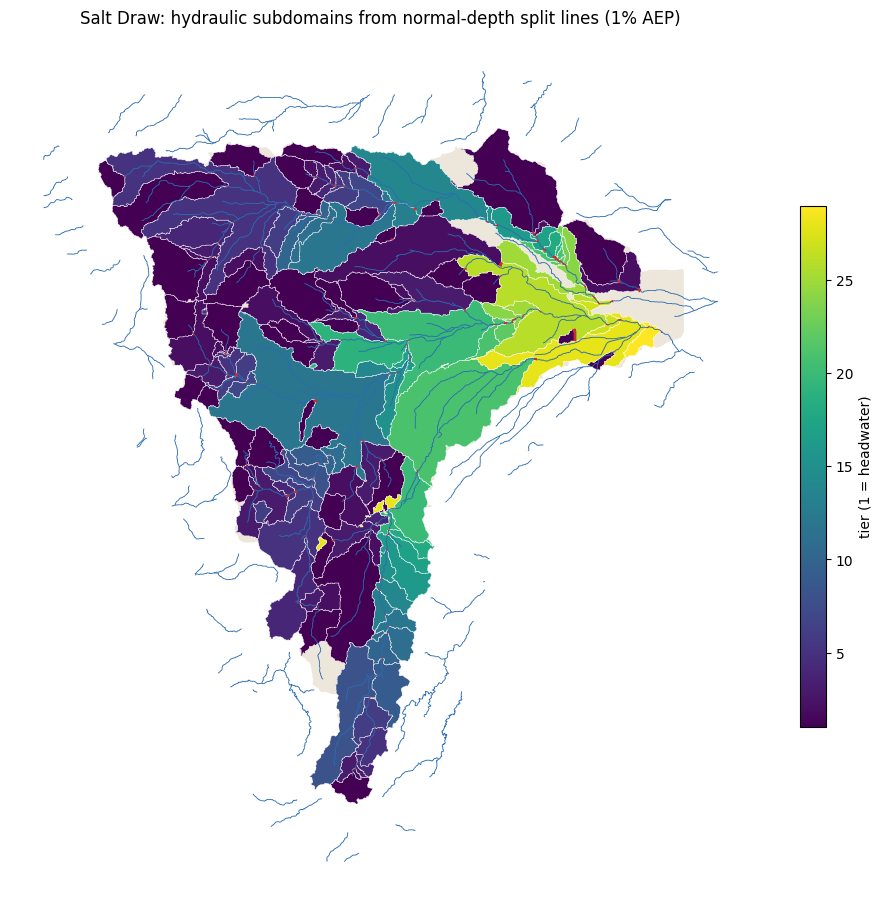

In [7]:
fig, ax = plt.subplots(figsize=(11, 9), constrained_layout=True)
tiers = subdomains[subdomains["subdomain_id"] != partition.remainder_id]
subdomains[subdomains["subdomain_id"] == partition.remainder_id].plot(ax=ax, color="#ECE7DA", edgecolor="none")
tiers.plot(ax=ax, column="tier", cmap="viridis", edgecolor="white", linewidth=0.3, legend=True,
           legend_kwds={"label": "tier (1 = headwater)", "shrink": 0.6})
streams[streams["contributing_area_sqmi"] >= 5].to_crs(subdomains.crs).plot(ax=ax, color="#2B6CB0", linewidth=0.6)
search.split_lines.plot(ax=ax, color="#C53030", linewidth=2.0)
ax.set_title("Salt Draw: hydraulic subdomains from normal-depth split lines (1% AEP)")
ax.set_axis_off()
fig.savefig(FIG_DIR / "01_subdomains.png", dpi=130)
plt.show()

## 5. Choose one headwater subdomain

A headwater subdomain (tier 1) has no subdomain upstream, so the parent's
rainfall is its only forcing. The choice is rule-based: no labels (in
particular no closed-edge leakage over 5%), between 3 and 15 sq mi, and the
lowest closed-edge exchange.

In [8]:
event = search.events[0]
pick = subdomains[(subdomains["tier"] == 1) & subdomains["labels"].apply(len).eq(0)
                  & subdomains["area_sqmi"].between(3, 15)].sort_values(f"leak_fraction_{event}")
display(pick[["subdomain_id", "cell_count", "area_sqmi", f"leak_fraction_{event}"]].head())
HEADWATER = pick["subdomain_id"].iloc[0]
line = search.split_lines.set_index("split_line_id").loc[int(HEADWATER)]
print(f"headwater {HEADWATER}: {int(pick.iloc[0]['cell_count']):,} cells, {pick.iloc[0]['area_sqmi']:.2f} sq mi; "
      f"outlet normal-depth slope {line['normal_depth_slope']:.4f} (TauDEM link slope {line['link_slope']:.4f})")

,subdomain_id,cell_count,area_sqmi,leak_fraction_1pct
13,2800,2407,5.116011,0.004056
24,3433,4000,8.217961,0.010855
15,3081,2517,5.689533,0.038894


headwater 2800: 2,407 cells, 5.12 sq mi; outlet normal-depth slope 0.0071 (TauDEM link slope 0.0138)


## 6. Author and validate the breakout

`plan_breakouts` writes nothing. It records the exact parent cells and the BC
lines, and runs `RasBreakout2D.preflight` on the parent. `apply_breakouts`
copies the parent project (without its result HDFs) to `05_breakout`. There it
clones plan, geometry and unsteady file, cuts the clone to the parent's exact
cells in HEC-RAS 6.6, and writes the BC lines and their forcing.

HEC-RAS can misclassify a BC line drawn exactly on the perimeter, or assign a
short line to the whole ring. So every line is checked against its compiled
external faces after each preprocess, and a failing line moves to its next
placement variant. The child keeps the parent's time step, meteorology and
initial conditions.

In [9]:
breakout_plan = RasSubdomain.plan_breakouts(partition, "01", ras_object=parent, subdomain_ids=[HEADWATER])
display(breakout_plan.checks)
assert breakout_plan.is_ready
t0 = time.time()
breakouts = RasSubdomain.apply_breakouts(breakout_plan, BREAKOUT_DIR, overwrite_dest=True)
print(f"authored in {(time.time() - t0) / 60:.1f} min")
placement = breakouts.preparation[HEADWATER]["bc_placement"]
display(pd.DataFrame(placement["attempts"])[["attempt", "placements", "external_faces", "failing"]])
checks = RasSubdomain.validate_breakouts(breakouts)
display(checks)
assert not checks["blocking"].any()

2026-10-24 11:58:17 - ras_commander.RasBreakout2D - INFO - 2D breakout preflight sd_2800: ready=True, features=4102


,subdomain_id,check,passed,blocking,detail
0,*,parent_geometry_matches_search,True,False,SLDR_004.g02.hdf matches the searched mesh
1,2800,single_polygon_boundary,True,False,child boundary is Polygon with 0 holes
2,2800,has_outflow_boundary,True,False,1 outlet and 1 perimeter normal-depth lines
3,2800,breakout_preflight,True,False,ready


2026-10-24 11:58:18 - ras_commander.RasPrj - INFO - ras-commander v0.96.2 | An open-source project of CLB Engineering Corporation (https://clbengineering.com/) | Docs: https://rascommander.info | GitHub: https://github.com/gpt-cmdr/ras-commander


2026-10-24 11:58:18 - ras_commander.RasPrj - INFO - Project initialized: SLDR_004


2026-10-24 11:58:18 - ras_commander.RasPrj - INFO - Using HEC-RAS version 6.6


...

2026-10-24 12:00:45 - ras_commander.RasPreprocess - INFO - Starting HEC-RAS preprocessing for plan 08


2026-10-24 12:00:45 - ras_commander.RasBco - INFO - Monitoring SLDR_004.bco08 for 'Starting Unsteady Flow Computations' signal...


2026-10-24 12:00:58 - ras_commander.RasBco - INFO - Detected owned RasUnsteady.exe startup with complete preprocessing artifacts


2026-10-24 12:00:58 - ras_commander.RasPreprocess - WARNING - Could not establish preprocessing process ownership: Process name is unavailable


,subdomain_id,check,passed,blocking,detail
0,2800,bc_line_placement,True,False,3 placement pass(es)
1,2800,preprocess,True,False,geometry and event conditions written
2,2800,bc_line:Out_ND_2800,True,False,4 of 91 external faces
3,2800,bc_line:Edge_ND_1,True,False,87 of 91 external faces


## 7. Run the headwater breakout

In [10]:
runs = RasSubdomain.compute_subdomains(breakouts, max_workers=1, num_cores=NUM_CORES)
display(runs)
assert runs["success"].all()

2026-10-24 12:00:58 - ras_commander.RasCmdr - INFO - Filtered plans to execute: ['08']


2026-10-24 12:00:58 - ras_commander.RasCmdr - INFO - Adjusted max_workers to 1 based on the number of plans to compute: 1


2026-10-24 12:01:00 - ras_commander.RasCmdr - INFO - Prepared 1 worker folder(s) for parallel execution


2026-10-24 12:01:00 - ras_commander.ExecutionArtifacts - INFO - Removed plan 08 execution artifact: SLDR_004.bco08


2026-10-24 12:01:56 - ras_commander.RasCmdr - INFO - Plan 08 in worker 1: Successful


2026-10-24 12:01:56 - ras_commander.RasCmdr - INFO - Consolidating worker artifacts back to original project folder: Input


2026-10-24 12:01:59 - ras_commander.RasCmdr - INFO - Consolidated 3 worker artifact(s) to Input


2026-10-24 12:01:59 - ras_commander.RasCmdr - INFO - Execution results: 1/1 plan(s) successful


,subdomain_id,tier,plan_number,success,tier_wall_clock_s,plan_hdf_path
0,2800,1,08,True,61.615633,C:\Users\bill\AppData\Local\clb-gen3\scratch-s...


## 8. Compare with the parent

The breakout keeps the parent's cells, so every child cell is compared with the
same parent cell (matched by centre). Maximum WSE is compared over cells wet
above 0.1 ft in both models. The outlet hydrograph is the child's Normal Depth
outlet flow against the parent's native flow across the same faces.

In [11]:
comparison = RasSubdomain.compare_to_parent(breakouts, parent_hdf)
display(comparison.T)

,0
subdomain_id,2800
status,compared
cells,2407
cells_matched_to_parent,2407
wet_cells_compared,2407
wse_diff_p50_ft,0.001465
wse_diff_p95_ft,0.018408
wse_diff_p99_ft,0.084443
wse_diff_max_ft,0.263184
wse_diff_mean_ft,-0.001262


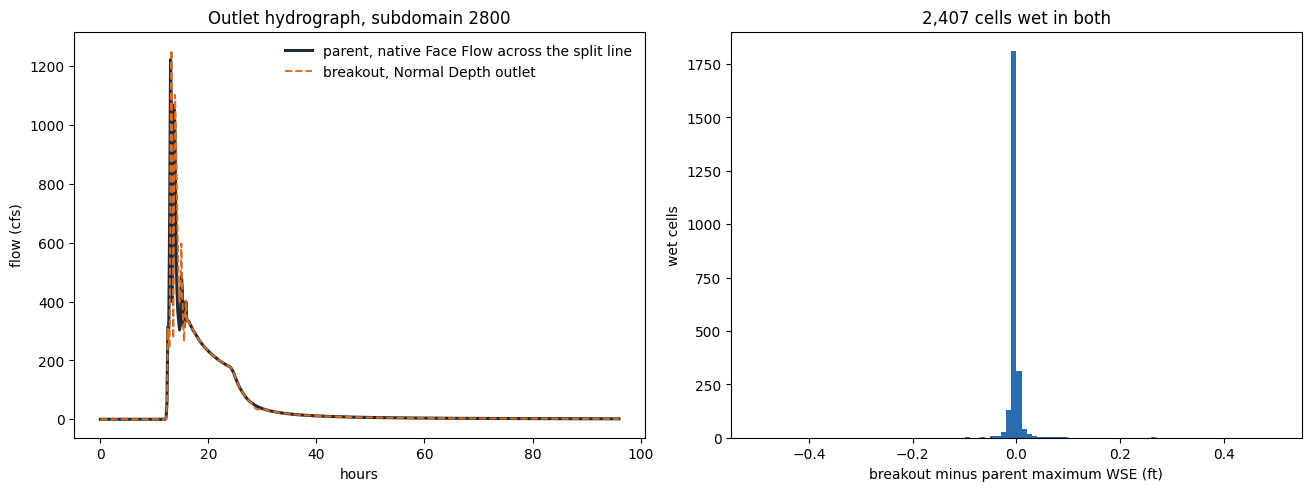

In [12]:
from ras_commander.hdf import HdfResultsMesh
from ras_commander.subdomain._breakouts import _bc_flow
from ras_commander.subdomain._parent import EventReader

child_hdf = Path(runs["plan_hdf_path"].iloc[0])
lines = search._context["lines"]
outlet = lines[int(HEADWATER)]
reader = EventReader(parent_hdf, "SLDR_004")
ids, flow = reader.series("Face Flow", outlet["faces"])
col = {int(f): i for i, f in enumerate(ids)}
parent_q = (flow[:, [col[int(f)] for f in outlet["faces"]]] * np.asarray(outlet["signs"])).sum(axis=1)
parent_h = reader.seconds() / 3600
child_h, child_q = _bc_flow(child_hdf, [f"Out_ND_{HEADWATER}"])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), constrained_layout=True)
axes[0].plot(parent_h, parent_q, color="#1F2937", linewidth=2.2, label="parent, native Face Flow across the split line")
axes[0].plot(child_h, child_q, color="#DD6B20", linewidth=1.4, linestyle="--", label="breakout, Normal Depth outlet")
axes[0].set(xlabel="hours", ylabel="flow (cfs)", title=f"Outlet hydrograph, subdomain {HEADWATER}")
axes[0].legend(frameon=False)

geometry = read_geometry(child_hdf, "SLDR_004")
from scipy.spatial import cKDTree
_, idx = cKDTree(parent_geometry.cell_center).query(geometry.cell_center)
cw = HdfResultsMesh.get_mesh_summary_values(child_hdf, "Maximum Water Surface").set_index("cell_id")["maximum_water_surface"]
pw = HdfResultsMesh.get_mesh_summary_values(parent_hdf, "Maximum Water Surface").set_index("cell_id")["maximum_water_surface"]
c_w = cw.reindex(np.arange(geometry.cell_count)).to_numpy()
p_w = pw.reindex(idx).to_numpy()
wet = ((c_w - geometry.cell_min_elevation) > 0.1) & ((p_w - parent_geometry.cell_min_elevation[idx]) > 0.1)
axes[1].hist((c_w - p_w)[wet], bins=np.linspace(-0.5, 0.5, 101), color="#2B6CB0")
axes[1].set(xlabel="breakout minus parent maximum WSE (ft)", ylabel="wet cells",
            title=f"{int(wet.sum()):,} cells wet in both")
fig.savefig(FIG_DIR / "02_outlet_and_wse.png", dpi=130)
plt.show()

## Findings and limits

The tables above report; they do not pass or fail. On the Salt Draw 1% AEP
parent, the search accepted 148 normal-depth split lines in 29 tiers. The
headwater subdomain chosen above has 2,407 parent cells over 5.1 sq mi, and its
closed edges exchanged 0.4% of its outlet volume in the parent. It ran on its
own in about a minute and reproduced the parent closely:

- **Maximum WSE:** within 0.0015 ft at the median and 0.018 ft at the 95th
  percentile; the largest difference is 0.26 ft. The wet extent is identical.
- **Outlet:** peak +2.6%, volume +2.0%, peak one output interval (10 min)
  later, NSE 0.89 against the parent's native flow across the same faces.

**Why the child is held at the parent's time step.** With the step it inherits
(30 s, Courant-adaptive), the same child differed by up to 3.1 ft (p95
0.67 ft). The parent's adaptive step fell to 15 s at 12:03 on the event day,
forced by its most restrictive cells elsewhere in the HUC. The child alone
stayed at 30 s until 12:30, and a transient at its wetting front set its
summary maxima high. `apply_breakouts(time_step="parent_minimum")`, the
default, fixes the child at the parent's shortest step. 2D results are not
reproducible to 0.01 ft over large areas even run to run, so differences of
this size are what a faithful breakout looks like.

**What this does and does not show.** One headwater subdomain behaves as a
project-level breakout of the parent with simple normal-depth boundaries. The
tiered run of the whole HUC, with hydrograph hand-off into downstream
subdomains, is implemented (`compute_subdomains`) but is not run here.

**Parent preparation in this copy.** The parent geometry and its Face Flow run
are the HEC-RAS 6.6 parent prepared for the fim-commander Salt Draw research.
That preparation added 98 longest-face midpoint seeds to the delivered mesh,
checked at the model's face-length ratio of 0.05. The notebook checked that
the run and the geometry share an identical mesh before using them.

**Limits of this release:**

- feet models only;
- subdomains with holes, more than one part, or a structure on a split line
  are refused at planning;
- the inflow hand-off rewrites the downstream inline hydrograph and
  preprocesses again;
- `GeomMesh.plan_computation_point_repair` does not yet complete on the
  delivered Salt Draw mesh at its strictest face-length ratio (0.1).

**Roadmap:**

- an isolated subdomain around a project point or polygon, with its
  downstream and upstream boundary lines found automatically;
- the full-HUC tiered run with a parity table, on the fleet;
- interior subdomains with holes;
- SI units.
